# Analisando Grafos do SNAP: web-flickr (G114)

In [1]:
from src.config import SEED, DATA_RAW

## Leitura do grafo

Uma vista rápida da lista de arestas bruta baixada do SNAP em `data/raw/`, ainda sem nenhum tratamento: contagens, graus e a vizinhança de um vértice.

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

from src.io import read_edge_list

### Contagens brutas

O arquivo comprimido é lido em fluxo, sem o cabeçalho. O grau bruto de um vértice é o número de linhas em que ele aparece.

In [3]:
raw_edges = read_edge_list(DATA_RAW / "flickrEdges.txt.gz")
edge_array = np.array(raw_edges, dtype=np.int64)
vertex_ids, raw_degrees = np.unique(edge_array, return_counts=True)
pd.Series({"linhas de arestas": len(raw_edges), "vértices distintos": len(vertex_ids)})

linhas de arestas     2316948
vértices distintos     105938
dtype: int64

### Histograma dos graus brutos

O eixo vertical está em escala log para que as faixas de grau alto, com poucos vértices, fiquem visíveis.

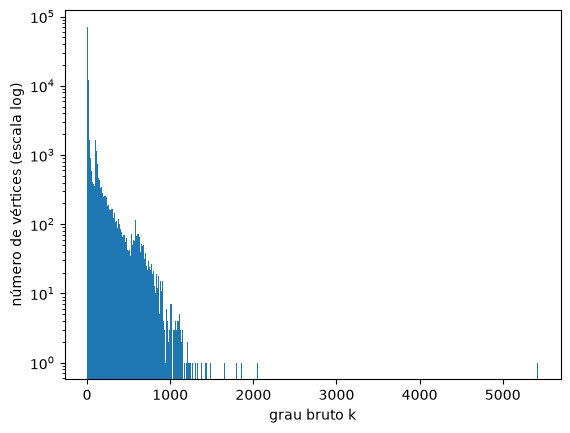

In [4]:
figure, axes = plt.subplots()
axes.hist(raw_degrees, bins="auto")
axes.set_yscale("log")
axes.set_xlabel("grau bruto k")
axes.set_ylabel("número de vértices (escala log)")
plt.show()

### Vizinhança de um vértice

Um vértice é sorteado com a semente `SEED`, e o subgrafo induzido por ele e pelos seus vizinhos é filtrado da lista de arestas, sem montar o grafo inteiro em memória no networkx.

In [5]:
rng = np.random.default_rng(SEED)
center_vertex = int(rng.choice(vertex_ids))

touches_center = (edge_array[:, 0] == center_vertex) | (edge_array[:, 1] == center_vertex)
neighborhood_vertices = np.unique(edge_array[touches_center])
has_both_ends_in_neighborhood = np.isin(edge_array, neighborhood_vertices).all(axis=1)
neighborhood_graph = nx.Graph(edge_array[has_both_ends_in_neighborhood].tolist())

pd.Series(
    {
        "vértice sorteado": center_vertex,
        "vértices na vizinhança": neighborhood_graph.number_of_nodes(),
        "arestas na vizinhança": neighborhood_graph.number_of_edges(),
    }
)

vértice sorteado          528275245
vértices na vizinhança          157
arestas na vizinhança          3750
dtype: int64

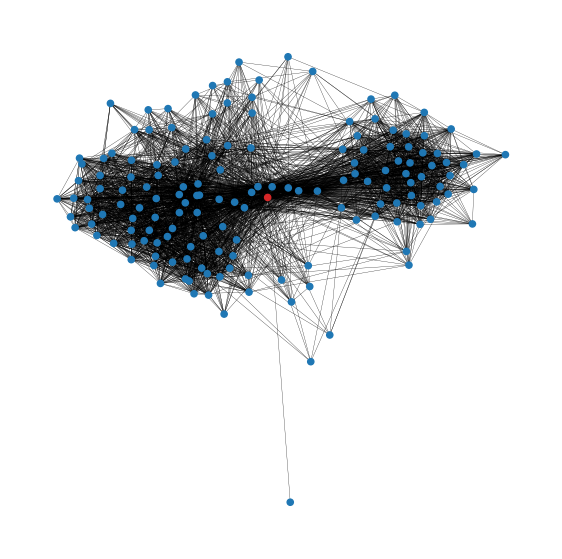

In [6]:
layout = nx.spring_layout(neighborhood_graph, seed=SEED)
vertex_colors = ["tab:red" if v == center_vertex else "tab:blue" for v in neighborhood_graph]

figure, axes = plt.subplots(figsize=(7, 7))
nx.draw_networkx(
    neighborhood_graph, layout, ax=axes, node_color=vertex_colors,
    node_size=20, width=0.2, with_labels=False,
)
axes.set_axis_off()
plt.show()

## Tratamento dos dados

A lista bruta vira um grafo simples não direcionado, com vértices de 0 a n − 1, e dele se extrai a maior componente conexa. Os dois conjuntos e o mapa de IDs vão para `data/processed/`.

In [7]:
import numpy as np
import pandas as pd

from src.config import DATA_RAW, DATA_PROCESSED, TABLES_DIR
from src.io import read_edge_list, write_edge_list
from src.tratamento import (
    extract_largest_component,
    reindex_vertices,
    remove_duplicate_edges,
    remove_self_loops,
)

### Grafo simples e maior componente

Cada par é uma aresta não ordenada. Os auto-laços e as arestas repetidas saem, e os vértices são renumerados na ordem do ID original. A maior componente recebe numeração própria.

In [8]:
raw_edges = np.array(read_edge_list(DATA_RAW / "flickrEdges.txt.gz"))
edges_without_self_loops = remove_self_loops(raw_edges)
deduplicated_edges = remove_duplicate_edges(edges_without_self_loops)
simple_edges, original_ids = reindex_vertices(deduplicated_edges)
lcc_edges, lcc_vertices = extract_largest_component(simple_edges, len(original_ids))

assert (simple_edges[:, 0] < simple_edges[:, 1]).all(), "o grafo simples tem auto-laços"
assert len(np.unique(simple_edges, axis=0)) == len(simple_edges), "o grafo simples tem arestas repetidas"

### Gravação

O mapa liga cada vértice ao ID original e ao índice na maior componente, vazio para quem está fora dela. A compressão grava sem data no cabeçalho, para que reexecutar não altere os arquivos versionados.

In [9]:
write_edge_list(simple_edges, DATA_PROCESSED / "flickr_simples.edgelist.gz")
write_edge_list(lcc_edges, DATA_PROCESSED / "flickr_lcc.edgelist.gz")

id_map = pd.DataFrame({"original_id": original_ids})
id_map["lcc_vertex"] = pd.Series(range(len(lcc_vertices)), index=lcc_vertices, dtype="Int64")
id_map.to_csv(
    DATA_PROCESSED / "mapa_ids.csv.gz",
    index_label="vertex",
    compression={"method": "gzip", "mtime": 0},
)

### Tabela antes × depois

In [10]:
treatment_table = pd.DataFrame(
    {
        "Lista bruta": [
            len(np.unique(raw_edges)),
            len(raw_edges),
            len(raw_edges) - len(edges_without_self_loops),
            len(edges_without_self_loops) - len(deduplicated_edges),
        ],
        "Grafo simples": [len(original_ids), len(simple_edges), 0, 0],
        "Maior componente": [len(lcc_vertices), len(lcc_edges), 0, 0],
    },
    index=["Vértices", "Arestas", "Auto-laços", "Arestas repetidas"],
)
treatment_table.style.format(thousands=".").to_latex(TABLES_DIR / "tratamento.tex", hrules=True)
treatment_table

,Lista bruta,Grafo simples,Maior componente
Vértices,105938,105938,105722
Arestas,2316948,2316948,2316668
Auto-laços,0,0,0
Arestas repetidas,0,0,0
